In [1]:
%pip install earthaccess xarray h5netcdf cartopy matplotlib numpy pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import cartopy.crs as ccrs
import earthaccess
import h5netcdf
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

c:\Users\scarl\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
auth = earthaccess.login(persist=True)

In [ ]:
results = earthaccess.search_data(
    short_name="PACE_OCI_L1A_SCI",
    granule_name="PACE_OCI.20250212T180315.L1A.nc",
)
paths = earthaccess.download(results, local_path="granules")
datatree = xr.open_datatree(paths[0])
datatree

c:\Users\scarl\AppData\Local\Programs\Python\Python313\Lib\site-packages\earthaccess\results.py:348: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()
c:\Users\scarl\AppData\Local\Programs\Python\Python313\Lib\site-packages\earthaccess\store.py:838: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum(granule.size() for granule in granules) / 1024, 2)
QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 148.10it/s]
PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]Could not remove temporary file: c:\Users\scarl\Desktop\KELP\granules\partial__1lr16se


In [ ]:
tspan = ("2024-05-01", "2024-05-07")
bbox = (-76.75, 36.97, -75.74, 39.01)
results = earthaccess.search_data(
    short_name="PACE_OCI_L1B_SCI",
    temporal=tspan,
    bounding_box=bbox,
)
paths = earthaccess.open(results)

/usr/local/lib/python3.12/dist-packages/earthaccess/results.py:348: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()
/usr/local/lib/python3.12/dist-packages/earthaccess/store.py:523: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum([granule.size() for granule in granules]) / 1024, 2)


QUEUEING TASKS | :   0%|          | 0/11 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/11 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/11 [00:00<?, ?it/s]

In [ ]:
datatree = xr.open_datatree(paths[0])
datatree

<xarray.DataTree>
Group: /
│   Attributes: (12/36)
│       title:                             PACE OCI Level-1B Data
│       instrument:                        OCI
│       platform:                          PACE
│       processing_level:                  L1B
│       cdm_data_type:                     swath
│       geospatial_lat_units:              degrees_north
│       ...                                ...
│       time_coverage_start:               2024-05-01T16:53:11.072Z
│       time_coverage_end:                 2024-05-01T16:58:10.954Z
│       processing_version:                3.0.2
│       identifier_product_doi_authority:  https://dx.doi.org
│       identifier_product_doi:            10.5067/PACE/OCI/L1B/SCI/3
│       history:                           2026-05-07T14:16:40Z: l1bgen_oci ephfi...
├── Group: /sensor_band_parameters
│       Dimensions:                (blue_bands: 119, red_bands: 163, SWIR_bands: 9,
│                                   HAM_sides: 2, polarization_coefficients: 3,
│                                   number_of_taps: 16)
│       Dimensions without coordinates: blue_bands, red_bands, SWIR_bands, HAM_sides,
│                                       polarization_coefficients, number_of_taps
│       Data variables: (12/16)
│           blue_wavelength        (blue_bands) float32 476B ...
│           blue_solar_irradiance  (blue_bands) float32 476B ...
│           red_wavelength         (red_bands) float32 652B ...
│           red_solar_irradiance   (red_bands) float32 652B ...
│           SWIR_wavelength        (SWIR_bands) float32 36B ...
│           SWIR_bandpass          (SWIR_bands) float32 36B ...
│           ...                     ...
│           red_m13_coef           (red_bands, HAM_sides, polarization_coefficients) float32 4kB ...
│           SWIR_m12_coef          (SWIR_bands, HAM_sides, polarization_coefficients) float32 216B ...
│           SWIR_m13_coef          (SWIR_bands, HAM_sides, polarization_coefficients) float32 216B ...
│           blue_spectral_mode     (number_of_taps) float32 64B ...
│           red_spectral_mode      (number_of_taps) float32 64B ...
│           SWIR_gain_type         (SWIR_bands) float32 36B ...
│       Attributes:
│           spatial_aggregation_factor:  8
├── Group: /scan_line_attributes
│       Dimensions:             (scans: 1710)
│       Dimensions without coordinates: scans
│       Data variables:
│           time                (scans) datetime64[ns] 14kB ...
│           spin_ID             (scans) float64 14kB ...
│           HAM_side            (scans) float32 7kB ...
│           scan_quality_flags  (scans) float32 7kB ...
├── Group: /geolocation_data
│       Dimensions:         (scans: 1710, pixels: 1272)
│       Coordinates:
│           latitude        (scans, pixels) float32 9MB ...
│           longitude       (scans, pixels) float32 9MB ...
│       Dimensions without coordinates: scans, pixels
│       Data variables:
│           height          (scans, pixels) float32 9MB ...
│           watermask       (scans, pixels) float32 9MB ...
│           sensor_azimuth  (scans, pixels) float64 17MB ...
│           sensor_zenith   (scans, pixels) float64 17MB ...
│           solar_azimuth   (scans, pixels) float64 17MB ...
│           solar_zenith    (scans, pixels) float64 17MB ...
│           quality_flag    (scans, pixels) float32 9MB ...
├── Group: /navigation_data
│       Dimensions:           (scans: 1710, quaternion_elements: 4, vector_elements: 3,
│                              pixels: 1272)
│       Dimensions without coordinates: scans, quaternion_elements, vector_elements,
│                                       pixels
│       Data variables:
│           att_quat          (scans, quaternion_elements) float32 27kB ...
│           att_ang           (scans, vector_elements) float32 21kB ...
│           orb_pos           (scans, vector_elements) float32 21kB ...
│           orb_vel           (scans, vector_elements) float32 21kB ...
│           sun_

In [ ]:
datatree["observation_data"]["rhot_blue"].sizes

Frozen({'blue_bands': 119, 'scans': 1710, 'pixels': 1272})

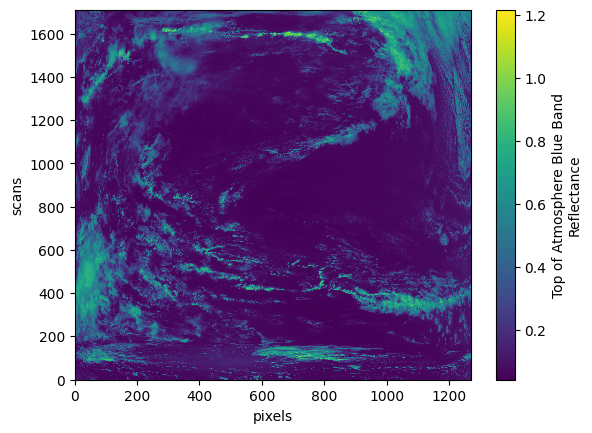

In [ ]:
plot = datatree["observation_data"]["rhot_blue"].sel({"blue_bands": 100}).plot()

In [ ]:
clouds = (0, 50)
results = earthaccess.search_data(
    short_name="PACE_OCI_L2_AOP",
    temporal=tspan,
    bounding_box=bbox,
    cloud_cover=clouds,
)
paths = earthaccess.open(results)

/usr/local/lib/python3.12/dist-packages/earthaccess/results.py:348: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()
/usr/local/lib/python3.12/dist-packages/earthaccess/store.py:523: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum([granule.size() for granule in granules]) / 1024, 2)


QUEUEING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/3 [00:00<?, ?it/s]

In [ ]:
datatree = xr.open_datatree(paths[0], decode_timedelta=False)
rrs = datatree["geophysical_data"]["Rrs"]
for item in ("longitude", "latitude"):
    rrs[item] = datatree["navigation_data"][item]
rrs

<xarray.DataArray 'Rrs' (number_of_lines: 1709, pixels_per_line: 1272,
                         wavelength: 172)> Size: 1GB
[373901856 values with dtype=float32]
Coordinates:
  * wavelength  (wavelength) float32 688B 346.0 348.5 350.9 ... 716.8 719.3
    longitude   (number_of_lines, pixels_per_line) float32 9MB ...
    latitude    (number_of_lines, pixels_per_line) float32 9MB ...
Dimensions without coordinates: number_of_lines, pixels_per_line
Attributes:
    long_name:      Remote sensing reflectance
    units:          sr^-1
    standard_name:  surface_ratio_of_upwelling_radiance_emerging_from_sea_wat...
    valid_min:      -30000
    valid_max:      25000

/usr/local/lib/python3.12/dist-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


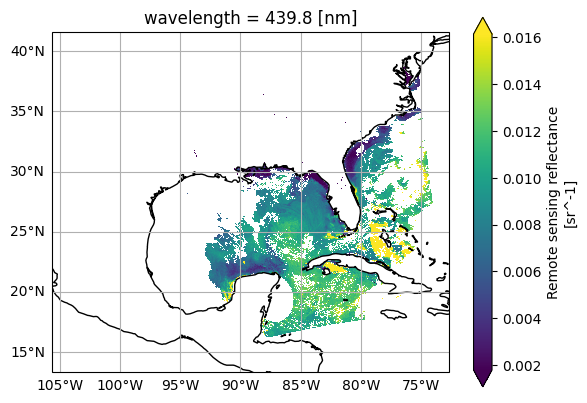

In [ ]:
rrs_sel = rrs.sel({"wavelength": 440}, method="nearest")
fig, ax = plt.subplots(subplot_kw={"projection": ccrs.PlateCarree()})
im = rrs_sel.plot(x="longitude", y="latitude", cmap="viridis", robust=True, ax=ax)
ax.gridlines(draw_labels={"left": "y", "bottom": "x"})
ax.coastlines()
plt.show()

In [ ]:
results = earthaccess.search_data(
    short_name="PACE_OCI_L3M_RRS",
    granule_name="*.MO.*.4km.*",
    temporal=tspan,
)
paths = earthaccess.open(results)

/usr/local/lib/python3.12/dist-packages/earthaccess/results.py:348: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()
/usr/local/lib/python3.12/dist-packages/earthaccess/store.py:523: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum([granule.size() for granule in granules]) / 1024, 2)


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


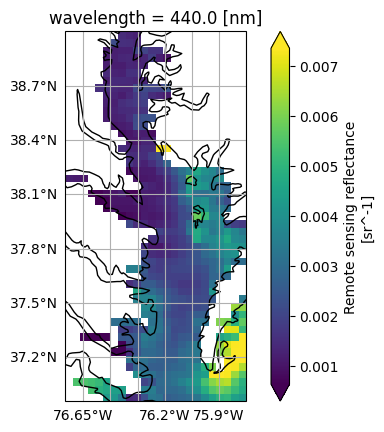

In [ ]:
dataset = xr.open_dataset(paths[0])
rrs = dataset["Rrs"]
rrs_440_bbox = rrs.sel({
    "wavelength": 440,
    "lat": slice(bbox[3], bbox[1]),
    "lon": slice(bbox[0], bbox[2]),
})
fig, ax = plt.subplots(subplot_kw={"projection": ccrs.PlateCarree()})
im = rrs_440_bbox.plot(x="lon", y="lat", cmap="viridis", robust=True, ax=ax)
ax.gridlines(draw_labels={"left": "y", "bottom": "x"})
ax.coastlines()
plt.show()

In [ ]:
results = earthaccess.search_data(
    short_name="PACE_OCI_L3M_CHL",
    temporal=tspan,
    granule_name="*.DAY.*.0p1deg.*",
)
paths = earthaccess.open(results)
dataset = xr.open_mfdataset(paths, combine="nested", concat_dim="date")
dates = [xr.open_dataset(i).attrs["time_coverage_end"] for i in paths]
dt = pd.to_datetime(dates)
dataset = dataset.assign_coords(date=dt.values)

/usr/local/lib/python3.12/dist-packages/earthaccess/results.py:348: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  self["size"] = self.size()
/usr/local/lib/python3.12/dist-packages/earthaccess/store.py:523: FutureWarning: As of version 1.0, `DataGranule.size` will be accessed as an attribute; e.g. use `DataCollection.size` **not** `DataCollection.size()`
  total_size = round(sum([granule.size() for granule in granules]) / 1024, 2)


QUEUEING TASKS | :   0%|          | 0/7 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/7 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/7 [00:00<?, ?it/s]

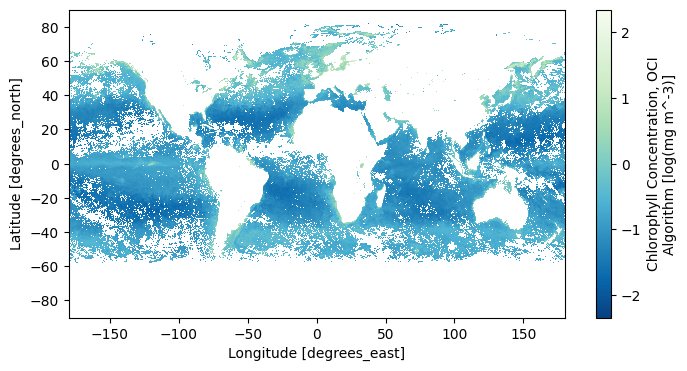

In [ ]:
chla = np.log10(dataset["chlor_a"])
chla.attrs.update({"units": f'log({dataset["chlor_a"].attrs["units"]})'})
chla_avg = chla.mean("date", keep_attrs=True)
im = chla_avg.plot(aspect=2, size=4, cmap="GnBu_r")